In [ ]:
# import library

# standar library
import os
import json
import warnings
import joblib

# data & visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# preprocess
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV, cross_val_predict, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# model
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# metrik evaluasi
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, recall_score,
    precision_score, f1_score, balanced_accuracy_score, roc_auc_score,
    average_precision_score, precision_recall_curve, roc_curve
)

# konfigurassi global
RANDOM_STATE = 42
warnings.filterwarnings("ignore")

In [ ]:
# load dataset
df = pd.read_csv('/content/heart-disease-dataset.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
# informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
# deskripsi dataset
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


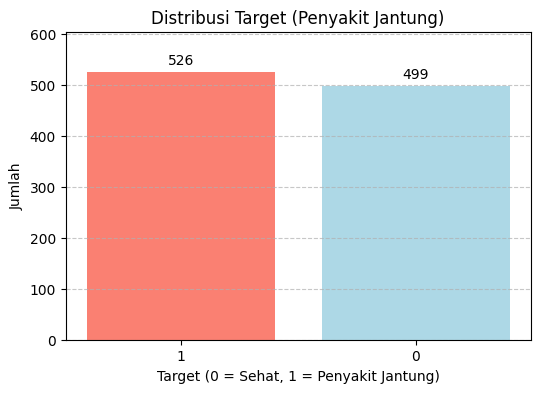

In [ ]:
# visualisasi distribussi target
target_counts = df['target'].value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(target_counts.index.astype(str), target_counts.values, color=['salmon', 'lightblue'])

plt.bar_label(bars, padding=3)

plt.title('Distribusi Target (Penyakit Jantung)')
plt.xlabel('Target (0 = Sehat, 1 = Penyakit Jantung)')
plt.ylabel('Jumlah')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, max(target_counts.values) * 1.15)
plt.show()

In [ ]:
# cek baris & kolom
df.shape

(1025, 14)

In [ ]:
# cek missing value
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
# cek duplikasi data
df.duplicated().sum()

np.int64(723)

In [ ]:
# hapus duplikasi data
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [ ]:
# baris dan kolom setelah hapus duplikasi data
df.shape

(302, 14)

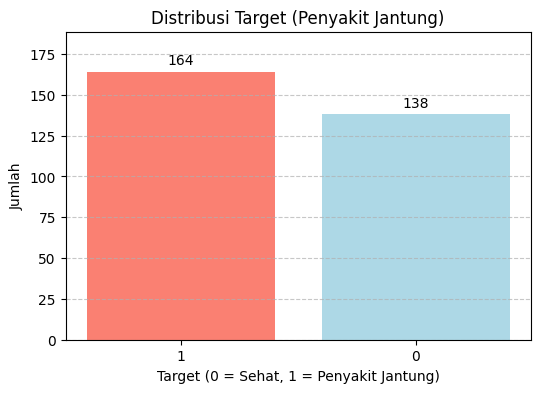

In [ ]:
# visualisasi distribussi target setelah hapus duplikasi data
target_counts = df['target'].value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(target_counts.index.astype(str), target_counts.values, color=['salmon', 'lightblue'])

plt.bar_label(bars, padding=3)

plt.title('Distribusi Target (Penyakit Jantung)')
plt.xlabel('Target (0 = Sehat, 1 = Penyakit Jantung)')
plt.ylabel('Jumlah')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, max(target_counts.values) * 1.15)
plt.show()

In [ ]:
# pisah fitur (X) dengan target (y)
X = df.drop(columns=['target'])
y = df['target']

# bagi data 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

In [ ]:
# scaling data
preprocessor = Pipeline(steps=[
    ('scaler', StandardScaler())
])

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

features_names = X_train.columns
X_train_scaled = pd.DataFrame(X_train_preprocessed, columns=features_names)
X_test_scaled = pd.DataFrame(X_test_preprocessed, columns=features_names)

X_train_scaled.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,1.421944,-1.445595,0.986493,-0.973041,5.882908,-0.398314,-1.008059,0.408240,-0.652714,0.527263,-0.697127,-0.722716,1.075838
1,-0.465841,0.691757,-0.954281,0.756507,-0.885696,-0.398314,-1.008059,-1.104705,1.532065,-0.083233,-0.697127,-0.722716,1.075838
2,0.422528,0.691757,-0.954281,-0.197726,-0.588175,-0.398314,-1.008059,-0.882213,1.532065,1.050546,-0.697127,2.132606,1.075838
3,1.644036,0.691757,0.986493,0.517949,0.118437,-0.398314,-1.008059,-0.214737,-0.652714,0.876119,-0.697127,2.132606,1.075838
4,-1.021072,-1.445595,0.016106,-1.151959,-1.629499,-0.398314,0.875214,-0.570724,-0.652714,-0.868157,-0.697127,-0.722716,-0.544643


 MODEL: Naive Bayes 

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.82      0.78        28
           1       0.83      0.76      0.79        33

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61



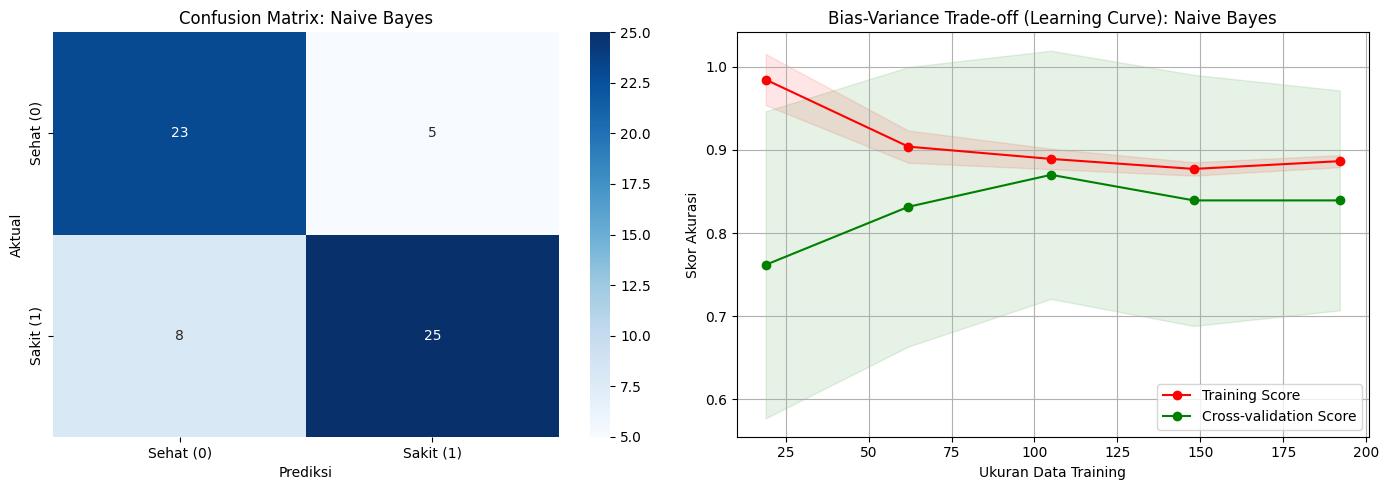




 MODEL: Logistic Regression 

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



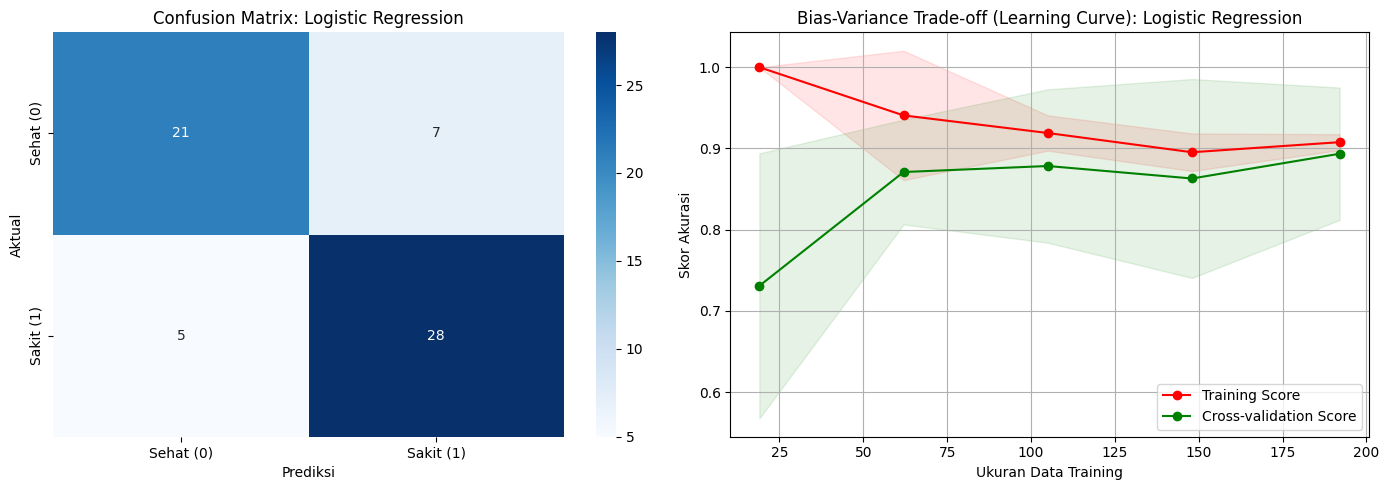




 MODEL: K-Nearest Neighbors 

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.71      0.75        28
           1       0.78      0.85      0.81        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



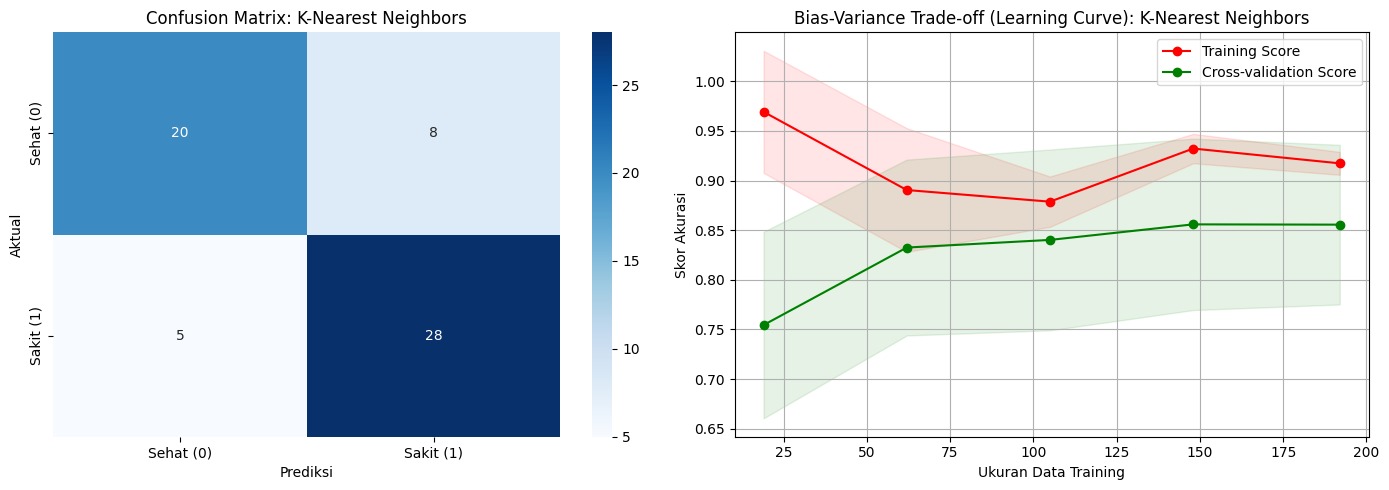




 MODEL: Support Vector Machine 

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.71      0.74        28
           1       0.77      0.82      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



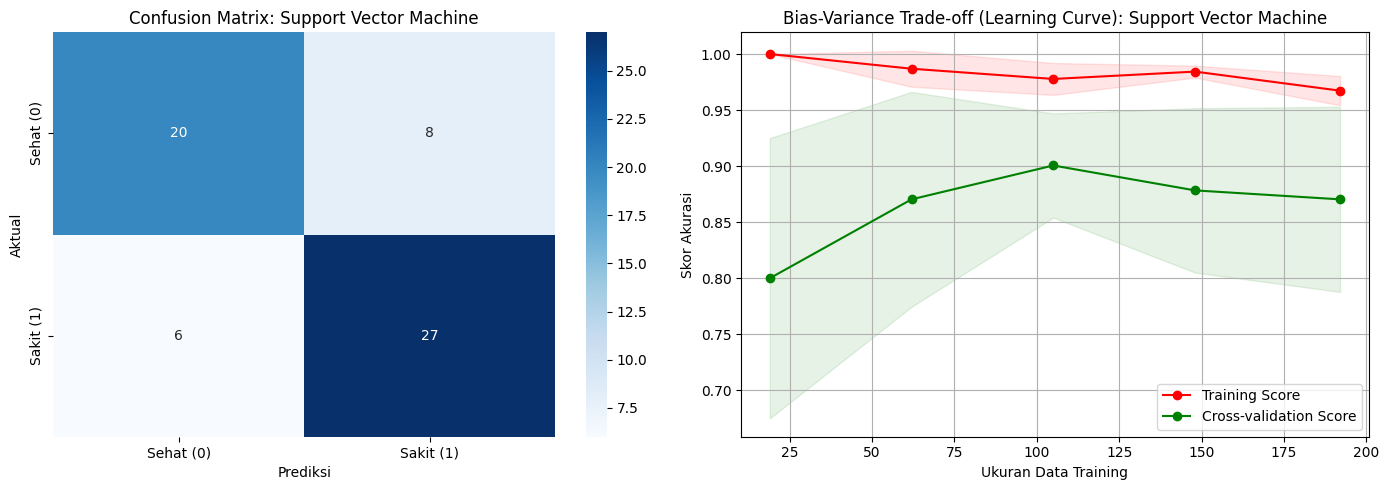




 MODEL: Decision Tree 

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



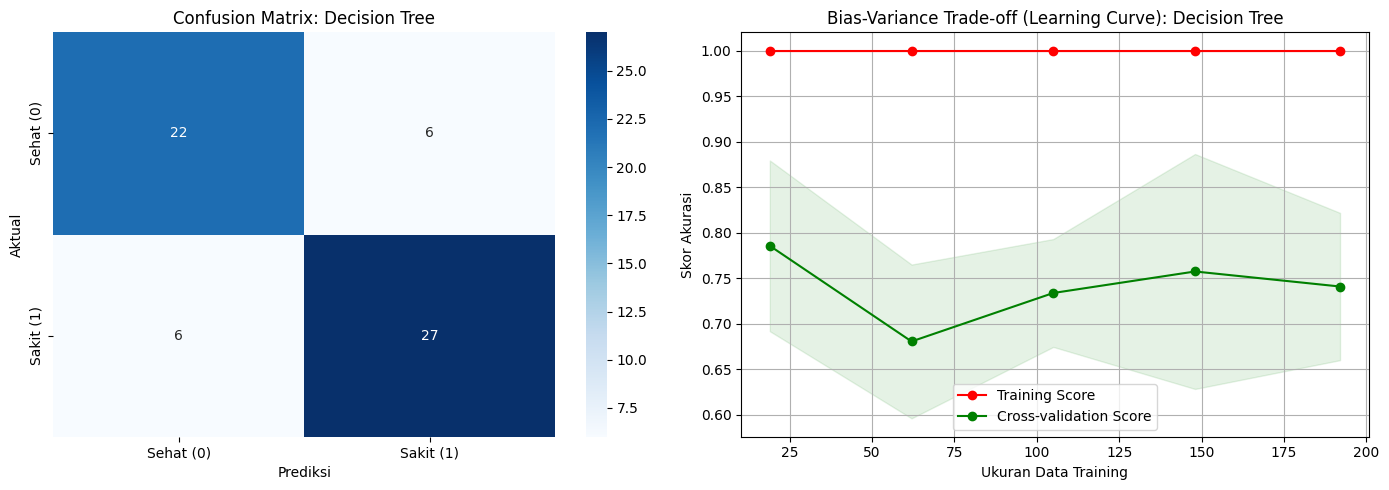




 MODEL: Random Forest 

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



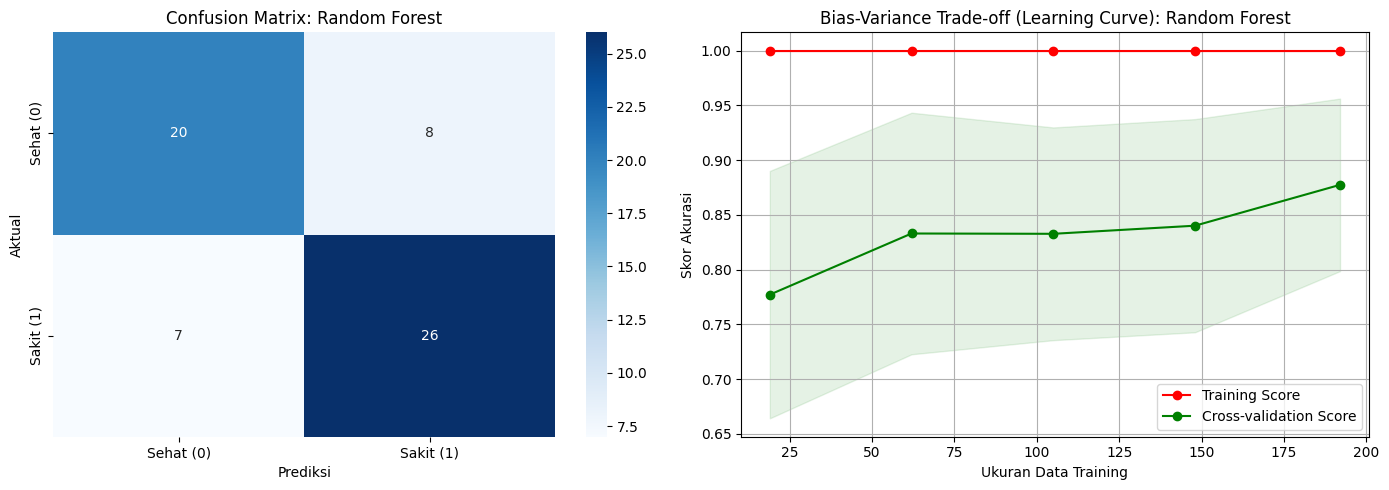




 MODEL: Gradient Boosting 

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.68      0.69        28
           1       0.74      0.76      0.75        33

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61



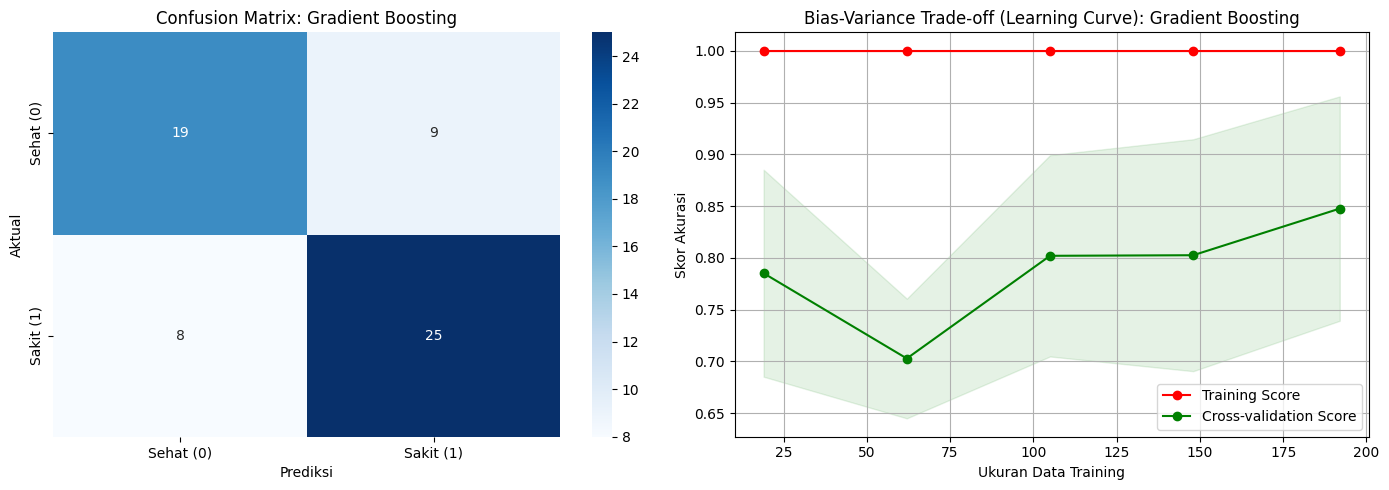




 MODEL: XGBoost 

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.68      0.69        28
           1       0.74      0.76      0.75        33

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61



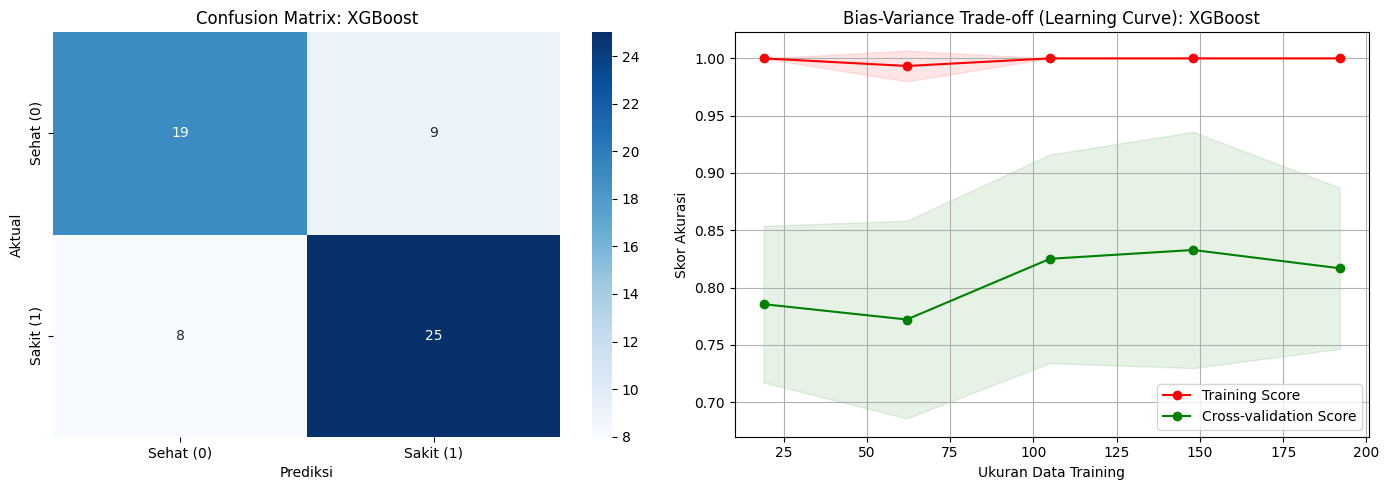




 RINGKASAN EVALUASI MODEL 
                        Accuracy  Recall  Precision  F1-Score
Naive Bayes               0.7869  0.7576     0.8333    0.7937
Logistic Regression       0.8033  0.8485     0.8000    0.8235
K-Nearest Neighbors       0.7869  0.8485     0.7778    0.8116
Support Vector Machine    0.7705  0.8182     0.7714    0.7941
Decision Tree             0.8033  0.8182     0.8182    0.8182
Random Forest             0.7541  0.7879     0.7647    0.7761
Gradient Boosting         0.7213  0.7576     0.7353    0.7463
XGBoost                   0.7213  0.7576     0.7353    0.7463


In [ ]:
# definisi daftar model
models = {
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Support Vector Machine': SVC(probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

performance_summary = {}

for name, model in models.items():
    print("="*80)
    print(f" MODEL: {name} ")
    print("="*80)

    # train model
    model.fit(X_train_scaled, y_train)

    # prediksi
    y_pred = model.predict(X_test_scaled)

    # hitung metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    performance_summary[name] = {
        'Accuracy': acc,
        'Recall': rec,
        'Precision': prec,
        'F1-Score': f1
    }

    # 1. classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # 2. visualisasi confusion matrix & trade-off bias-variance (learning curve)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Sehat (0)', 'Sakit (1)'],
                yticklabels=['Sehat (0)', 'Sakit (1)'])
    axes[0].set_title(f'Confusion Matrix: {name}')
    axes[0].set_xlabel('Prediksi')
    axes[0].set_ylabel('Aktual')

    # plot learning curve (bias vs variance trade-off)
    # learning curve untuk melihat training vs validation
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='recall',
        train_sizes=np.linspace(0.1, 1.0, 5), random_state=RANDOM_STATE
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    axes[1].plot(train_sizes, train_mean, 'o-', color='r', label='Training Score')
    axes[1].plot(train_sizes, test_mean, 'o-', color='g', label='Cross-validation Score')
    axes[1].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
    axes[1].fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='g')

    axes[1].set_title(f'Bias-Variance Trade-off (Learning Curve): {name}')
    axes[1].set_xlabel('Ukuran Data Training')
    axes[1].set_ylabel('Skor Akurasi')
    axes[1].legend(loc='best')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()
    print("\n\n")

# ringkasan semua model
df_summary = pd.DataFrame(performance_summary).T
print("="*80)
print(" RINGKASAN EVALUASI MODEL ")
print("="*80)
print(df_summary.round(4))

Mengoptimalkan Logistic Regression...
Parameter Terbaik untuk Logistic Regression: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}

Mengoptimalkan K-Nearest Neighbors...
Parameter Terbaik untuk K-Nearest Neighbors: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}

Mengoptimalkan Decision Tree...
Parameter Terbaik untuk Decision Tree: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}

 MODEL HASIL TUNING: Logistic Regression 

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



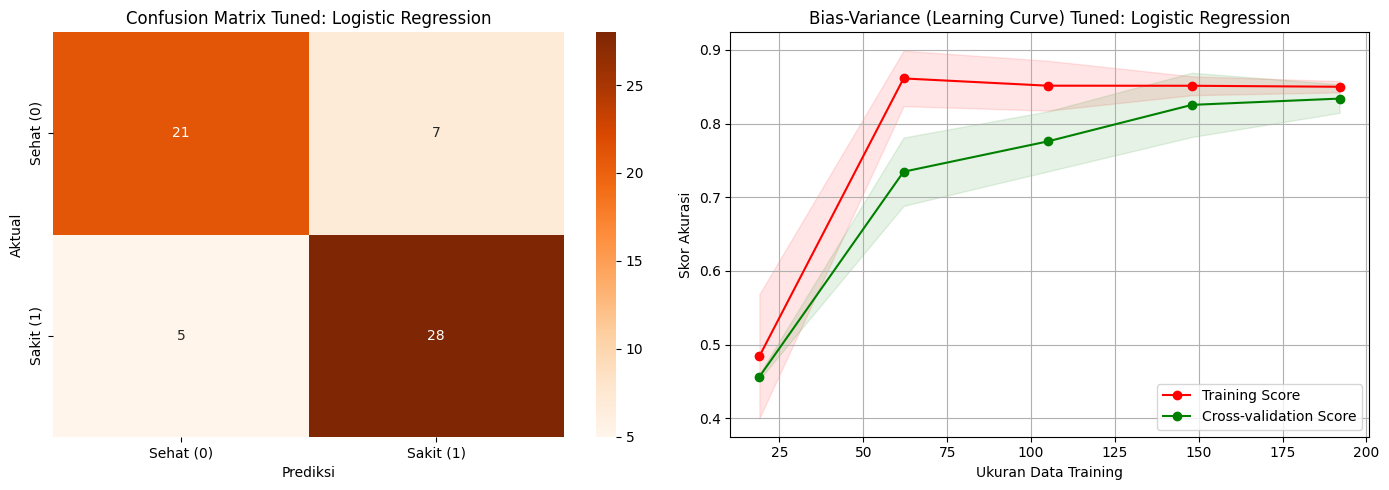




 MODEL HASIL TUNING: K-Nearest Neighbors 

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.71      0.77        28
           1       0.78      0.88      0.83        33

    accuracy                           0.80        61
   macro avg       0.81      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61



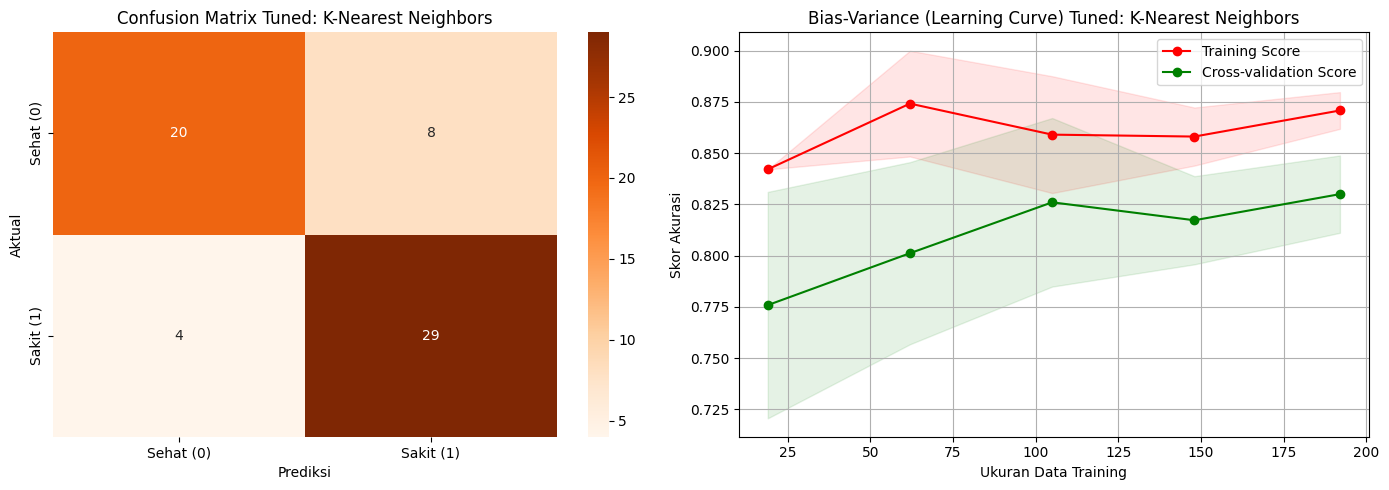




 MODEL HASIL TUNING: Decision Tree 

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.71      0.70        28
           1       0.75      0.73      0.74        33

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61



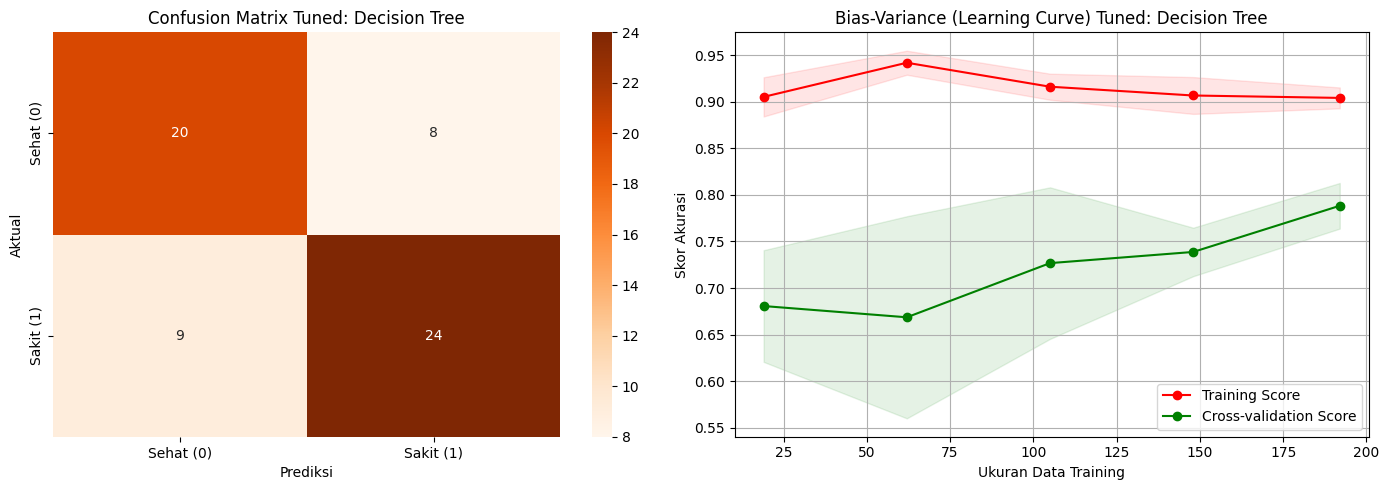




 PERBANDINGAN MODEL BASELINE VS MODEL TUNED 
                     Accuracy (Baseline)  Accuracy (Tuned)  Recall (Baseline)  \
Logistic Regression               0.8033            0.8033             0.8485   
K-Nearest Neighbors               0.7869            0.8033             0.8485   
Decision Tree                     0.8033            0.7213             0.8182   

                     Recall (Tuned)  Precision (Baseline)  Precision (Tuned)  \
Logistic Regression          0.8485                0.8000             0.8000   
K-Nearest Neighbors          0.8788                0.7778             0.7838   
Decision Tree                0.7273                0.8182             0.7500   

                     F1-Score (Baseline)  F1-Score (Tuned)  
Logistic Regression               0.8235            0.8235  
K-Nearest Neighbors               0.8116            0.8286  
Decision Tree                     0.8182            0.7385  


In [ ]:
# definisi hyperparameter grid untuk masing masing model
param_grids = {
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear', 'saga']
    },
    'K-Nearest Neighbors': {
        'n_neighbors': [3, 5, 7, 9, 11, 15],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    },
    'Decision Tree': {
        'max_depth': [3, 5, 7, 10, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'criterion': ['gini', 'entropy']
    }
}

# model baseline
baseline_models = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE)
}

tuned_models = {}
tuned_performance = {}

# tuning menggunakan gridsearch (dioptimalkan berdasarkan f1-score)
for name, model in baseline_models.items():
    print(f"Mengoptimalkan {name}...")
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring='f1',
        n_jobs=-1
    )
    grid_search.fit(X_train_scaled, y_train)
    best_model = grid_search.best_estimator_
    tuned_models[name] = best_model
    print(f"Parameter Terbaik untuk {name}: {grid_search.best_params_}\n")

# evaluasi model hasil tuning
for name, model in tuned_models.items():
    print("="*80)
    print(f" MODEL HASIL TUNING: {name} ")
    print("="*80)

    # prediksi menggunakan model yang sudah di-tuning
    y_pred = model.predict(X_test_scaled)

    # hitung metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    tuned_performance[name] = {
        'Accuracy (Tuned)': acc,
        'Recall (Tuned)': rec,
        'Precision (Tuned)': prec,
        'F1-Score (Tuned)': f1
    }

    # 1. classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # 2. visualisasi confusion matrix & learning curve
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # plot confusion matrix
    cm_tuned = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
                xticklabels=['Sehat (0)', 'Sakit (1)'],
                yticklabels=['Sehat (0)', 'Sakit (1)'])
    axes[0].set_title(f'Confusion Matrix Tuned: {name}')
    axes[0].set_xlabel('Prediksi')
    axes[0].set_ylabel('Aktual')

    # plot learning curve (bias vs variance trade-off)
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 5), random_state=RANDOM_STATE
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    axes[1].plot(train_sizes, train_mean, 'o-', color='r', label='Training Score')
    axes[1].plot(train_sizes, test_mean, 'o-', color='g', label='Cross-validation Score')
    axes[1].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
    axes[1].fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='g')

    axes[1].set_title(f'Bias-Variance (Learning Curve) Tuned: {name}')
    axes[1].set_xlabel('Ukuran Data Training')
    axes[1].set_ylabel('Skor Akurasi')
    axes[1].legend(loc='best')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()
    print("\n\n")

# 3. perbandingan hasil baseline vs hasil tuning
baseline_summary = pd.DataFrame(performance_summary).T.loc[['Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree']]
baseline_summary.columns = [f"{col} (Baseline)" for col in baseline_summary.columns]

tuned_df = pd.DataFrame(tuned_performance).T

comparison_df = pd.concat([baseline_summary, tuned_df], axis=1)
comparison_df = comparison_df[[
    'Accuracy (Baseline)', 'Accuracy (Tuned)',
    'Recall (Baseline)', 'Recall (Tuned)',
    'Precision (Baseline)', 'Precision (Tuned)',
    'F1-Score (Baseline)', 'F1-Score (Tuned)'
]]

print("="*95)
print(" PERBANDINGAN MODEL BASELINE VS MODEL TUNED ")
print("="*95)
print(comparison_df.round(4))

In [ ]:
# menyimpan model terbaik (knn tuned) dan preprocessor pipeline
best_model_knn = tuned_models['K-Nearest Neighbors']

# simpan model
model_filename = 'best_knn_model.joblib'
joblib.dump(best_model_knn, model_filename)
print(f"Model terbaik berhasil disimpan ke: {model_filename}")

# simpan preprocessor scaler untuk menjamin konsistensi preprocessing data baru
preprocessor_filename = 'preprocessor_scaler.joblib'
joblib.dump(preprocessor, preprocessor_filename)
print(f"Scaler preprocessor berhasil disimpan ke: {preprocessor_filename}")

Model terbaik berhasil disimpan ke: best_knn_model.joblib
Scaler preprocessor berhasil disimpan ke: preprocessor_scaler.joblib


In [ ]:
# menampilkan 5 data individu pertama untuk masing-masing target
print("="*50)
print("5 INDIVIDU DENGAN TARGET 0 (SEHAT)")
print("="*50)
data_target_0 = df[df['target'] == 0].head(5)
display(data_target_0)

print("\n" + "="*50)
print("5 INDIVIDU DENGAN TARGET 1 (PENYAKIT JANTUNG)")
print("="*50)
data_target_1 = df[df['target'] == 1].head(5)
display(data_target_1)

5 INDIVIDU DENGAN TARGET 0 (SEHAT)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



5 INDIVIDU DENGAN TARGET 1 (PENYAKIT JANTUNG)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
10,71,0,0,112,149,0,1,125,0,1.6,1,0,2,1
12,34,0,1,118,210,0,1,192,0,0.7,2,0,2,1
16,51,0,2,140,308,0,0,142,0,1.5,2,1,2,1
18,50,0,1,120,244,0,1,162,0,1.1,2,0,2,1
